# 11 · Stage 4: the switch-off law, the bench threshold and the growth budget

**Purpose.** Uses the per-run table of the bench $R_i$ sweeps (notebook 10) to (a) test the switch-off law of a single crossing in an $R_i$ sweep and extract the real threshold $G_c$, and (b) explain the critical rate with the growth budget: how much growth one pass above threshold allows at the critical rate, and what noise floor that implies.

**In the report.** Chapter 7, Secs. 7.4–7.5: Eqs. (7.2)–(7.4), Figs. 7.5–7.6, the sensitivity of $\Gamma_+$ to $G_c$ and the inferred noise floor $\delta$.

## Theory

**Switch-off in an $R_i$ sweep.** With $R_i = R_{i,c} + X$ and $X = \lambda t$, the decay accumulated after the crossing is (Eqs. 2.29–2.32)

$$\frac{\omega_0 (G_c - 1)}{2\lambda}\left[X - R_{i,c}\ln\!\left(1 + \frac{X}{R_{i,c}}\right)\right] = \Lambda_{\rm off}, \qquad R_{i,\rm off} \simeq R_{i,c} + k_i\sqrt{\lambda},\quad k_i = 2\sqrt{\frac{\Lambda_{\rm off}R_{i,c}}{\omega_0(G_c-1)}},$$

with $\Lambda_{\rm off} = \ln 10$ for a fall to 10 %. The intercept gives the threshold, $G_c = 1 + R_F/R_{i,c}$ (Eq. 7.4).

**Growth budget.** One pass above threshold allows growth by $e^{\Gamma_+}$ with

$$\Gamma_+ = \frac{\omega_0\,\Delta R}{\lambda}\sum_k (G_k - G_c)_+ . \tag{7.2}$$

At the critical rate this must equal $\ln(A_{\rm sat}/\delta)$ (Eq. 2.41), which gives the noise floor $\delta = A_{\rm sat}e^{-\Gamma_+(\lambda_c)}$. Because only a few positions lie above threshold, $\Gamma_+$ depends steeply on $G_c$: $\partial\Gamma_+/\partial G_c = -n_+\,\omega_0\Delta R/\lambda$, with $n_+$ the number of positions above threshold.

## Method

1. Keep the runs with a reliable trigger reference and a first switch-off (`time_origin_ok`, 18 of the 19 report runs).
2. Fit three laws by least squares: $R_{i,c} + k\sqrt{\lambda}$; a fixed delay $R_{i,c} + \lambda t_d$; and the exact law above with $R_{i,c}$ and $\Lambda_{\rm off}$ free and $G_c$ tied to $R_{i,c}$. Compare by rms residual and AIC.
3. $G_c$ from the square-root intercept; its uncertainty from the intercept's standard error.
4. With this $G_c$, compute $S_+$, $\Gamma_+$ at both edges of the critical-rate bracket (notebook 10), the implied $\delta$, and its uncertainty from the uncertainty of $G_c$.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
RUNS_CSV = "../data/stage4/results/bench_runs.csv"   # per-run table from notebook 10 (report: all 19 runs)
R_F = 90e3; RI_0 = 41e3; DELTA_RI = 10e3; N_STEPS = 31   # configuration B
R_WIEN, C_WIEN = 2.17e3, 1e-6
A_SAT = 11.25            # V, full amplitude on the bench
OUT_DIR = "outputs/11_stage4_budget"

## 1. Switch-off law fits

In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit, brentq
os.makedirs(OUT_DIR, exist_ok=True)
OMEGA0 = 1 / (R_WIEN * C_WIEN)
STEP_RI = DELTA_RI / N_STEPS

def X_off_exact(lam, Ric, Gc, Loff):
    """Exact switch-off overshoot X for R_i rising at rate lam (ohm/s): solves
       (omega0 (Gc-1) / (2 lam)) [X - Ric ln(1 + X/Ric)] = Loff."""
    out = []
    for l in np.atleast_1d(lam):
        a = 2 * Loff * l / (OMEGA0 * (Gc - 1))
        out.append(brentq(lambda X: X - Ric * np.log1p(X / Ric) - a, 1e-12, 50 * Ric))
    return np.array(out)


def fit_off_models(lam, Ri_off):
    """Fits three laws to switch-off resistances; returns a DataFrame of parameters and quality."""
    lam, y = np.asarray(lam, float), np.asarray(Ri_off, float)
    res = []
    def quality(f, p):
        r = y - f(lam, *p)
        rss = float((r ** 2).sum()); n = len(y); k = len(p)
        return np.sqrt(rss / n), n * np.log(rss / n) + 2 * k, r
    models = {
        "sqrt(lambda): Ric + k*sqrt(lambda)": (lambda l, Ric, k: Ric + k * np.sqrt(l), [43000.0, 10.0]),
        "fixed lag: Ric + lambda*dt": (lambda l, Ric, d: Ric + d * l, [44000.0, 0.05]),
    }
    for name, (f, p0) in models.items():
        p, cov = curve_fit(f, lam, y, p0=p0)
        rms, aic, r = quality(f, p)
        res.append(dict(model=name, p1=p[0], p1_err=np.sqrt(cov[0, 0]), p2=p[1], p2_err=np.sqrt(cov[1, 1]),
                        rms_ohm=rms, AIC=aic, f=f, p=p))
    # exact law: free Ric and Loff, Gc tied to Ric through Gc = 1 + R_F/Ric
    fe = lambda l, Ric, Loff: Ric + X_off_exact(l, Ric, 1 + R_F / Ric, Loff)
    p, cov = curve_fit(fe, lam, y, p0=[43000.0, 1.0], bounds=([30e3, 1e-3], [R_F / 2 - 1, 50]))
    rms, aic, r = quality(fe, p)
    res.append(dict(model="exact: Ric + X(lambda), X from the integral", p1=p[0], p1_err=np.sqrt(cov[0, 0]),
                    p2=p[1], p2_err=np.sqrt(cov[1, 1]), rms_ohm=rms, AIC=aic, f=fe, p=p))
    return pd.DataFrame(res)


runs = pd.read_csv(RUNS_CSV)
ok = runs.time_origin_ok.astype(str).str.lower().isin(["true", "1"]) & runs.Ri_first_off10.notna()
lam, Ri_off = runs.lambda_ohm_s[ok].to_numpy(float), runs.Ri_first_off10[ok].to_numpy(float)
fits = fit_off_models(lam, Ri_off)
print(f"{ok.sum()} runs used")
print(fits[["model", "p1", "p1_err", "p2", "p2_err", "rms_ohm", "AIC"]].round(3).to_string(index=False))

18 runs used
                                      model        p1  p1_err     p2  p2_err  rms_ohm     AIC
         sqrt(lambda): Ric + k*sqrt(lambda) 43250.041  55.873 14.871   0.704   27.841 123.755
                 fixed lag: Ric + lambda*dt 43814.509  31.859  0.096   0.005   29.931 126.360
exact: Ric + X(lambda), X from the integral 43259.641  54.983  1.184   0.113   27.845 123.760


## 2. Threshold and comparison with the predicted coefficient

In [3]:
Ric, Ric_err, k_fit, k_err = fits.iloc[0][["p1", "p1_err", "p2", "p2_err"]]
G_c = 1 + R_F / Ric; G_c_err = R_F * Ric_err / Ric**2
k_th = 2 * np.sqrt(np.log(10) * Ric / (OMEGA0 * (G_c - 1)))
dAIC = fits.AIC.iloc[1] - fits.AIC.iloc[0]
print(f"R_i,c = {Ric/1e3:.2f} +/- {Ric_err/1e3:.2f} kOhm -> G_c = {G_c:.3f} +/- {G_c_err:.3f}   [Eq. 7.4]")
print(f"k fitted {k_fit:.1f} +/- {k_err:.1f}, predicted k_i = {k_th:.1f} (ratio {k_fit/k_th:.2f});  AIC of fixed delay higher by {dAIC:.1f}")
print(f"exact law: Lambda_off = {fits.iloc[2].p2:.2f} +/- {fits.iloc[2].p2_err:.2f} (ln 10 = {np.log(10):.2f})")

R_i,c = 43.25 +/- 0.06 kOhm -> G_c = 3.081 +/- 0.003   [Eq. 7.4]
k fitted 14.9 +/- 0.7, predicted k_i = 20.4 (ratio 0.73);  AIC of fixed delay higher by 2.6
exact law: Lambda_off = 1.18 +/- 0.11 (ln 10 = 2.30)


## 3. Growth budget at the critical rate (Eq. 7.2)

In [4]:
ON, OFF = "switches back on every cycle", "stays off (never switches back on)"
lam_lo, lam_hi = runs[runs.state == ON].lambda_ohm_s.max(), runs[runs.state == OFF].lambda_ohm_s.min()
taps = np.arange(N_STEPS + 1); Gk = 1 + R_F / (RI_0 + STEP_RI * taps)
n_plus = int((Gk > G_c).sum()); S_plus = np.clip(Gk - G_c, 0, None).sum()
gam = {l: OMEGA0 * STEP_RI * S_plus / l for l in (lam_lo, lam_hi)}
delta = {l: A_SAT * np.exp(-g) for l, g in gam.items()}
dgam = n_plus * G_c_err * OMEGA0 * STEP_RI / np.mean([lam_lo, lam_hi])
print(f"positions above threshold: {n_plus} of {len(Gk)};  S+ = {S_plus:.4f}")
print(f"Gamma+ = {gam[lam_lo]:.2f} at {lam_lo/1e3:.2f} kOhm/s and {gam[lam_hi]:.2f} at {lam_hi/1e3:.2f} kOhm/s")
print(f"noise floor delta = {delta[lam_hi]*1e3:.2f} to {delta[lam_lo]*1e3:.2f} mV; uncertainty of G_c (+/- {G_c_err:.4f}) -> +/- {dgam:.2f} in Gamma+, a factor {np.exp(dgam):.1f} in delta")
print(f"sensitivity: a shift of G_c by 0.01 changes Gamma+ by {n_plus*0.01*OMEGA0*STEP_RI/np.mean([lam_lo, lam_hi]):.2f}")

positions above threshold: 7 of 32;  S+ = 0.4486
Gamma+ = 11.00 at 6.06 kOhm/s and 10.75 at 6.20 kOhm/s
noise floor delta = 0.24 to 0.19 mV; uncertainty of G_c (+/- 0.0027) -> +/- 0.46 in Gamma+, a factor 1.6 in delta
sensitivity: a shift of G_c by 0.01 changes Gamma+ by 1.70


## 4. Figures (as Figs. 7.5 and 7.6)

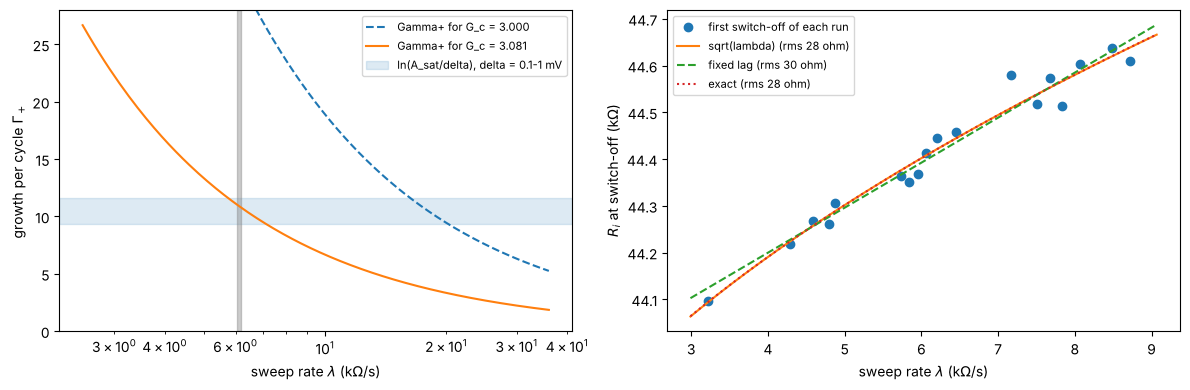

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ax = axs[0]; L = np.linspace(2500, 36000, 400)
for Gc_, ls in ((3.0, "--"), (G_c, "-")):
    ax.plot(L / 1e3, OMEGA0 * STEP_RI * np.clip(Gk - Gc_, 0, None).sum() / L, ls=ls, label=f"Gamma+ for G_c = {Gc_:.3f}")
ax.axhspan(np.log(A_SAT / 1e-3), np.log(A_SAT / 1e-4), color="tab:blue", alpha=0.15, label="ln(A_sat/delta), delta = 0.1-1 mV")
ax.axvspan(lam_lo / 1e3, lam_hi / 1e3, color="gray", alpha=0.4); ax.set_xscale("log")
ax.set_xlabel(r"sweep rate $\lambda$ (k$\Omega$/s)"); ax.set_ylabel(r"growth per cycle $\Gamma_+$"); ax.set_ylim(0, 28); ax.legend(fontsize=8)
ax = axs[1]; lg = np.linspace(lam.min() * 0.93, lam.max() * 1.04, 300)
ax.plot(lam / 1e3, Ri_off / 1e3, "o", label="first switch-off of each run")
for (_, fr), ls in zip(fits.iterrows(), ["-", "--", ":"]):
    ax.plot(lg / 1e3, fr.f(lg, *fr.p) / 1e3, ls=ls, label=f"{fr.model.split(':')[0]} (rms {fr.rms_ohm:.0f} ohm)")
ax.set_xlabel(r"sweep rate $\lambda$ (k$\Omega$/s)"); ax.set_ylabel(r"$R_i$ at switch-off (k$\Omega$)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "budget_and_switchoff.png"), dpi=150); plt.show()

## Check against the report

In [6]:
checks = {
    "Eq. 7.3: R_i,off = (43.25 +/- 0.06) kOhm + (14.9 +/- 0.7) sqrt(lambda), 18 runs": ok.sum() == 18 and abs(Ric - 43250) < 5 and abs(Ric_err - 60) < 5 and abs(k_fit - 14.9) < 0.05 and abs(k_err - 0.7) < 0.05,
    "rms 28 vs 30 ohm, AIC lower by 2.6": round(fits.rms_ohm.iloc[0]) == 28 and round(fits.rms_ohm.iloc[1]) == 30 and abs(dAIC - 2.6) < 0.05,
    "Eq. 7.4: G_c = 3.081 +/- 0.003": abs(G_c - 3.081) < 0.0005 and abs(G_c_err - 0.003) < 0.0005,
    "exact law: Lambda_off = 1.18 +/- 0.11": abs(fits.iloc[2].p2 - 1.18) < 0.005 and abs(fits.iloc[2].p2_err - 0.11) < 0.005,
    "predicted k_i = 20.4, fitted about three quarters of it": abs(k_th - 20.4) < 0.05 and abs(k_fit / k_th - 0.73) < 0.01,
    "seven positions above threshold": n_plus == 7,
    "Eq. 7.2: Gamma+ = 10.7 to 11.0 at the critical rate": abs(gam[lam_hi] - 10.7) < 0.06 and abs(gam[lam_lo] - 11.0) < 0.06,
    "delta about 0.2 mV, uncertain by a factor of about 1.6": 0.15e-3 < delta[lam_hi] < 0.25e-3 and abs(np.exp(dgam) - 1.6) < 0.1,
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)

PASS Eq. 7.3: R_i,off = (43.25 +/- 0.06) kOhm + (14.9 +/- 0.7) sqrt(lambda), 18 runs
PASS rms 28 vs 30 ohm, AIC lower by 2.6
PASS Eq. 7.4: G_c = 3.081 +/- 0.003
PASS exact law: Lambda_off = 1.18 +/- 0.11
PASS predicted k_i = 20.4, fitted about three quarters of it
PASS seven positions above threshold
PASS Eq. 7.2: Gamma+ = 10.7 to 11.0 at the critical rate
PASS delta about 0.2 mV, uncertain by a factor of about 1.6


## Using your own data

Any per-run table with the columns `lambda_ohm_s`, `Ri_first_off10`, `time_origin_ok` and `state` works (notebook 10 writes one). Change the configuration values for another circuit; `A_SAT` is your full oscillation amplitude.